# Remote care opportunity: results

**The question.** Which 3 medical specialisms offer the biggest opportunity for remote-care software in 2027? Asked by a health-tech company's product and market team (a fictional stakeholder; the data is real).

**What this notebook does.** It reads the finished results from the PostgreSQL database and turns them into two charts. Every number is calculated once, in the SQL views (`sql/04_views.sql`). The notebook only runs short `SELECT`s on those views and draws the result, so it can never disagree with `sql/05_analyse.sql`.

**How to run it.**
1. Build the database first: run `sql/01_schema.sql` to `sql/04_views.sql` in order (see the README).
2. Select the `.venv` kernel (packages in `requirements.txt`).
3. Run All.

## 1. Setup

Load the packages and connect to the local `remote_care` database. The connection needs no password on this machine, so no secret is stored in the notebook.

In [1]:
# load pandas (tables), create_engine (the database connection) and matplotlib (charts)
import pandas as pd
from sqlalchemy import create_engine
import matplotlib.pyplot as plt

In [2]:
# connect to the local remote_care database (no password needed on this machine)
engine = create_engine("postgresql+psycopg://localhost/remote_care")

## 2. National totals per year

**Prediction (written before running).** `v_national_year` returns 6 rows, one per year 2019 to 2024. Columns: `year`, `clinic`, `remote`, `all_consults`, `remote_share_pct`. 2024 `all_consults` = 19,791,058. The six years together add up to 113,939,420 (the check in `sql/04_views.sql`).

In [3]:
# ask the view for the national totals per year, oldest year first
national = pd.read_sql("SELECT * FROM v_national_year ORDER BY year", engine)
national

,year,clinic,remote,all_consults,remote_share_pct
0,2019,15882774.0,2912088.0,18794862.0,15.5
1,2020,10361609.0,7813487.0,18175096.0,43.0
2,2021,11636470.0,7130689.0,18767159.0,38.0
3,2022,12388963.0,6583389.0,18972352.0,34.7
4,2023,12755942.0,6682951.0,19438893.0,34.4
5,2024,12677043.0,7114015.0,19791058.0,35.9


In [4]:
# check: number of rows and columns, and the six-year total
print(national.shape)
print(national["all_consults"].sum())

(6, 5)
113939420.0


**Check: matches the prediction.** 6 rows and 5 columns, 2024 `all_consults` = 19,791,058, and the six years add up to 113,939,420, the same total as the check in `sql/04_views.sql`.

The counts show `.0` because PostgreSQL returns `SUM()` as a `numeric` type and pandas reads it as a decimal number. The values are exact.

## 3. Chart 1: does remote care last after COVID? (H2)

**Prediction (written before running).** Years 2019 to 2024 along the bottom, remote share (%) up the side. Lowest point 2019 (15.5%), highest 2020 (43.0%), then down to about 35% and flat, ending at 35.9% in 2024. The line never goes back near 2019.

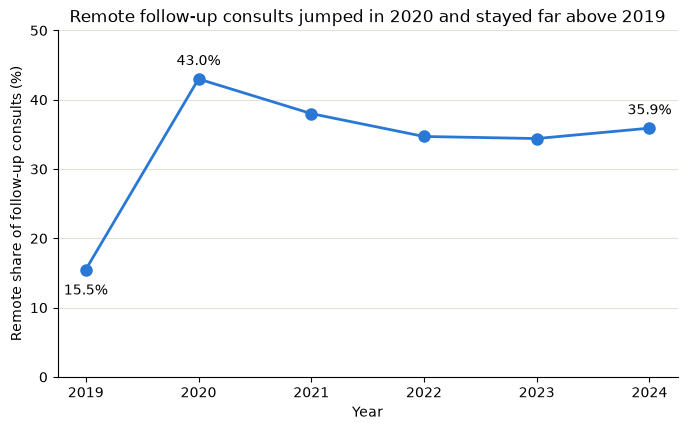

In [5]:
# draw the national remote share per year as one line

# an empty chart of a readable size (8 wide, 4.5 high)
fig, ax = plt.subplots(figsize=(8, 4.5))

# the line: year along the bottom, remote share up the side
ax.plot(national["year"], national["remote_share_pct"],
        color="#2a78d6", linewidth=2, marker="o", markersize=8)

# write the number next to 2019, 2020 and 2024 (2019 below its dot, the others above)
for year in [2019, 2020, 2024]:
    share = national.loc[national["year"] == year, "remote_share_pct"].iloc[0]
    above_or_below = -18 if year == 2019 else 10
    ax.annotate(f"{share}%", (year, share), textcoords="offset points",
                xytext=(0, above_or_below), ha="center")

# title says the finding; axis labels say the units
ax.set_title("Remote follow-up consults jumped in 2020 and stayed far above 2019")
ax.set_xlabel("Year")
ax.set_ylabel("Remote share of follow-up consults (%)")

# y-axis from 0 to 50, so 2019 is shown at its real size
ax.set_ylim(0, 50)

# quiet background: no top and right border, light horizontal grid lines
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e1e0d9")

# save the chart as an image for the README
fig.savefig("../docs/chart1_national_trend.png", dpi=150, bbox_inches="tight")

# show the chart under the cell
plt.show()

**What the chart shows.** In 2019, 15.5% of hospital follow-up consults were remote. In 2020 the share jumped to 43.0%. It came down after 2020 but levelled off around 35%, and in 2024 it was 35.9%: more than double 2019 (+20.4 percentage points), and rising again (+1.5 points on 2023). The same holds inside each specialism: all 26 specialisms with 2019 data were above their 2019 share in 2024 (Q5 in `sql/05_analyse.sql`).

**H2 is supported.** Remote follow-up care is a lasting part of Dutch hospital care, not a COVID spike. For the product team, the market is real and stable, so the question becomes where to aim (chart 2).

*Note: almost all remote follow-up care is by phone (98% in 2024, Q6), so "remote" here mostly means phone consults, not video.*

## 4. Chart 2: where is the biggest opportunity? (the answer)

**The rule (KPI 5, the same as Q8).** Keep the specialisms where remote care is proven (remote share at least 10% in 2024) and still growing (momentum above 0 since 2022). Rank them by headroom: the follow-up consults still done in the clinic in 2024, which could move to remote. The top 3 are the targets.

**Prediction (written before running).** 20 of 27 specialisms pass both filters (Q8). Top 3: internal medicine (about 1.6 million clinic follow-ups), surgery (about 1.4 million) and dermatology (about 1.1 million), with gynaecology just behind. The smallest specialisms have almost no bar.

In [6]:
# ask the growth view for the specialisms that pass both Q8 filters, largest headroom first
headroom = pd.read_sql("""
    SELECT specialism_code, specialism_name, clinic_2024, share_2024, momentum_pts
    FROM v_specialism_growth
    WHERE share_2024 >= 10        -- remote care proven (the same floor as Q8)
      AND momentum_pts > 0        -- still growing since 2022 (the same rule as Q8)
    ORDER BY clinic_2024 DESC
""", engine)
headroom

,specialism_code,specialism_name,clinic_2024,share_2024,momentum_pts
0,0313,Interne geneeskunde,1573274,44.9,0.3
1,0303,Chirurgie (Heelkunde),1369124,30.6,1.8
2,0310,Dermatologie en Venerologie,1095282,23.9,3.5
3,0307,"Medisch specialisten, obstetrie en gynaecologie",1041215,29.3,5.4
4,0305,"Medisch specialisten, orthopedie",906940,27.4,1.0
5,0302,"Medisch specialisten, keel-, neus- en oorheelk...",883506,20.5,1.8
6,0306,"Medisch specialisten, urologie",577575,44.5,0.4
7,0316,"Medisch specialisten, kindergeneeskunde",417493,49.7,4.9
8,0304,"Medisch specialisten, plastische chirurgie",275306,19.2,1.9
9,0389,Anesthesiologie,83736,68.8,2.8


In [7]:
# check: 20 specialisms pass, and the top 3 are the Q8 answer
print(len(headroom))
print(headroom["specialism_name"].head(3).tolist())

20
['Interne geneeskunde', 'Chirurgie (Heelkunde)', 'Dermatologie en Venerologie']


In [8]:
# English labels for the chart, by specialism code (the database keeps the official Dutch names)
english_names = {
    "0313": "Internal medicine", "0303": "Surgery", "0310": "Dermatology",
    "0307": "Obstetrics and gynaecology", "0305": "Orthopaedics", "0302": "Ear, nose and throat",
    "0306": "Urology", "0316": "Paediatrics", "0304": "Plastic surgery",
    "0389": "Anaesthesiology", "0361": "Radiotherapy", "0335": "Geriatrics",
    "0327": "Rehabilitation medicine", "8416": "Sports medicine", "0326": "Allergology",
    "0328": "Cardiothoracic surgery", "0390": "Clinical genetics", "0329": "Psychiatry",
    "0362": "Radiology", "1900": "Audiology centres",
}
headroom["label"] = headroom["specialism_code"].map(english_names)

# check: every specialism got an English name (expected 0 missing)
print(headroom["label"].isna().sum())

0


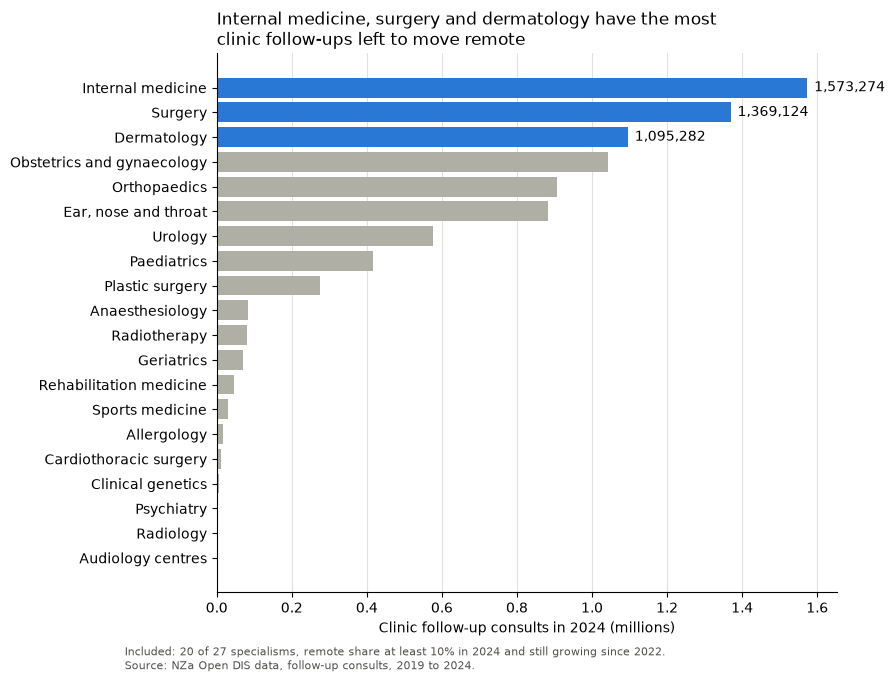

In [9]:
# draw the headroom ranking as horizontal bars, top 3 in blue, the rest in grey
fig, ax = plt.subplots(figsize=(8, 7))

# colour list: blue for positions 0, 1, 2 (the top 3), grey for the others
colours = ["#2a78d6" if position < 3 else "#b0afa6" for position in range(len(headroom))]

# horizontal bars: specialism on the side, clinic follow-ups along the bottom
ax.barh(headroom["label"], headroom["clinic_2024"], color=colours)

# largest at the top (matplotlib puts the first row at the bottom by default)
ax.invert_yaxis()

# write the exact number at the end of the three blue bars only
for position in range(3):
    value = headroom["clinic_2024"].iloc[position]
    ax.annotate(f"{value:,.0f}", (value, position), textcoords="offset points",
                xytext=(5, 0), va="center")

# title says the answer; the axis shows millions so the numbers stay short
ax.set_title("Internal medicine, surgery and dermatology have the most\nclinic follow-ups left to move remote", loc="left")
ax.set_xlabel("Clinic follow-up consults in 2024 (millions)")
ax.xaxis.set_major_formatter(lambda x, position: f"{x / 1_000_000:.1f}")

# quiet background: no top and right border, light vertical grid lines behind the bars
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", color="#e1e0d9")
ax.set_axisbelow(True)

# small note under the chart: which specialisms are included, and the data source
fig.text(0.01, 0.0, "Included: 20 of 27 specialisms, remote share at least 10% in 2024 and still growing since 2022.\n"
         "Source: NZa Open DIS data, follow-up consults, 2019 to 2024.", fontsize=8, color="#52514e")

# save the chart as an image for the README
fig.savefig("../docs/chart2_headroom.png", dpi=150, bbox_inches="tight")

# show the chart under the cell
plt.show()

**Why these three.** Internal medicine, surgery and dermatology pass both filters: remote care is proven there (44.9%, 30.6% and 23.9% of follow-ups were remote in 2024) and still growing since 2022 (+0.3, +1.8 and +3.5 points). They also have the most follow-ups still happening in the clinic: about 4 million together (4,037,680). That is the largest market left for remote-care software.

**Why not clinical genetics.** It has the highest remote share of all (85.9%), but only 5,925 follow-ups are still in the clinic. Almost everything that can move has already moved, so there is little left to win. A high share means a mature market, not a big opportunity.

**H3 is supported.** The best targets are large specialisms with a medium share that is still growing, not the specialisms with the highest share. None of the top 3 by remote share (clinical genetics, radiology, anaesthesiology) is in the top 3 by headroom (Q9).

**What to watch.**
- Internal medicine's momentum is only +0.3 points, so its growth may be levelling off. It is the least secure of the three.
- Gynaecology (1,041,215 clinic follow-ups, momentum +5.4) is very close behind dermatology and is the natural fourth target.
- The answer depends a little on the 10% floor: with a 15% floor the top 3 stays the same; with a 5% floor, ophthalmology (8.9% remote) replaces dermatology (Q10).